# Supplementary Figure 1. Reading the model out like the data

The model has no neurons, so its decoding z is modelled as `z = c dr + eta` (`nmdaint/readout.py`): the
cued-minus-uncued rate in 100 ms windows (dr), times a gain c, plus noise eta with the autocorrelation of
overlapping windows and a per-trial offset holding a share rho of the variance.
**a-d**: the read-out, its noise against the data's pre-cue z, and how c is calibrated. **e-i**: validation on
synthetic data, where the model drives Poisson neurons decoded with the recordings' pipeline
(`nmdaint/synthetic.py`). About 4 minutes.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from nmdaint import onoff, paths, ratemodel, readout, synthetic
from plots import figS1, style

## Parameters

In [2]:
P = ratemodel.params('nmda')
RHO = readout.RHO['all']               # noise share of the per-trial offset, all-units decoder
LEVELS = dict(synthetic.LEVELS)        # e-i: tuning strengths of the synthetic neurons (Hz at a 50 Hz pool rate),
TARGETS = dict(synthetic.TARGETS)      #      each matched to one of the data's decoders
N_SESSIONS = synthetic.N_SESSIONS      # e-i: synthetic sessions per strength

## The gain c
Set so that the model's decoding strength (upper mean of a two-Gaussian mixture of the delay z) equals the data's
mean over sessions (BUGS.md, B5: this figure's calibration, on 1,056 trials).

In [3]:
ses, hist = readout.load_data()
target = ses['all']['mu_on'].mean()
dw, tz = readout.rate_diff(ratemodel.simulate(P, 1056, seed=11))
delay = lambda t: (t >= 500) & (t <= 1400)
rng = np.random.default_rng(1)
eta = readout.noise(dw.shape, RHO, rng)
grid = 10 ** np.linspace(-2.6, -0.3, 15)
mus = readout.gain_curve(dw, eta, delay(tz), rng, grid)
c = readout.gain_for(target, mus, grid)
print(f'data decoding strength {target:.2f}; gain c = {c:.4f} z per Hz')

data decoding strength 2.18; gain c = 0.0510 z per Hz


findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.


findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive


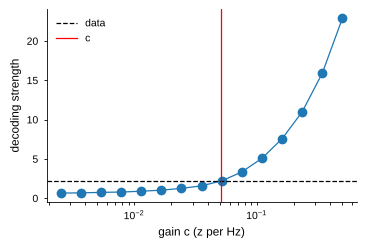

In [4]:
plt.figure(figsize=(4, 2.5))
plt.semilogx(grid, mus, 'o-'); plt.axhline(target, color='k', ls='--', label='data'); plt.axvline(c, color='r', label='c')
plt.xlabel('gain c (z per Hz)'); plt.ylabel('decoding strength'); plt.legend();

## a. One trial through the read-out

In [5]:
sim = ratemodel.simulate(P, 30, seed=5)
dw, tz = readout.rate_diff(sim)
rng = np.random.default_rng(4)
eta = readout.noise(dw.shape, RHO, rng)
valid = (tz >= 0) & (tz <= 1400)
st = onoff.label(c * dw + eta, readout.null_threshold(dw.shape, RHO, rng), valid)
k = int(np.argmax([(s[valid] == -1).sum() * (s[valid] == 1).sum() for s in st]))       # a trial with both states
m = dict(t=sim['t'], rc=sim['rc'][k], ru=sim['ru'][k], m=sim['m'][k], tz=tz, dw=dw[k], eta=eta[k],
         state=np.where(valid, st[k], 0), gain=c, rho=RHO)

## b. Noise: autocorrelation of the data's pre-cue z (no memory yet) vs the model's eta
The data's (`scripts/recordings.py`) for three decoded populations; the model's is
`(1 - rho) max(0, 1 - lag / 100 ms) + rho`.

In [6]:
acf = pd.read_csv(paths.results('recordings', 'precue_acf.csv'))
print('data at 200 ms:', acf[acf.lag_ms == 200].groupby('set').acf.mean().round(3).to_dict(), '; model rho:', readout.RHO)

data at 200 ms: {'all': 0.346, 'random20': 0.107, 'top20': 0.089} ; model rho: {'top': 0.09, 'random': 0.11, 'all': 0.35}


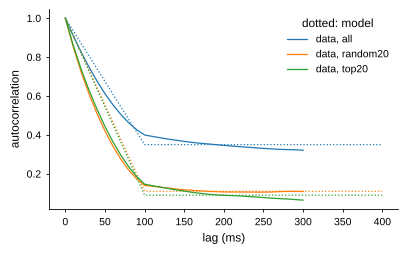

In [7]:
lag = np.arange(0, 401, 10)
plt.figure(figsize=(4.5, 2.6))
for (lab, a), col in zip(acf.groupby('set'), ('C0', 'C1', 'C2')):
    kind = 'all' if lab == 'all' else ('top' if lab.startswith('top') else 'random')
    m_ = a.groupby('lag_ms').acf.mean()
    plt.plot(m_.index, m_.values, color=col, label=f'data, {lab}')
    plt.plot(lag, (1 - readout.RHO[kind]) * np.maximum(0, 1 - lag / 100) + readout.RHO[kind], ':', color=col)
plt.xlabel('lag (ms)'); plt.ylabel('autocorrelation'); plt.legend(title='dotted: model');

## c, d. Calibration: the model's delay z and its decoding strength against c

In [8]:
simL = ratemodel.simulate(P, 600, seed=21)
dwL, tzL = readout.rate_diff(simL)
etaL = readout.noise(dwL.shape, RHO, np.random.default_rng(22))
m['delay_z'] = (c * dwL + etaL)[:, delay(tzL)].ravel()
m['mu_on_model'] = onoff.mu_on(m['delay_z'][None], np.random.default_rng(1))
m['grid'] = 10 ** np.linspace(-2.6, -0.6, 14)
m['mu_on_grid'] = [onoff.mu_on((g * dwL + etaL)[:, delay(tzL)], np.random.default_rng(1)) for g in m['grid']]
m['mu_on_data'] = target

## Play: the shared noise rho, at a fixed gain
A larger per-trial offset makes whole trials more On or more Off.

decoding strength: session 240209 2.22, mean of sessions 2.18, model 2.20


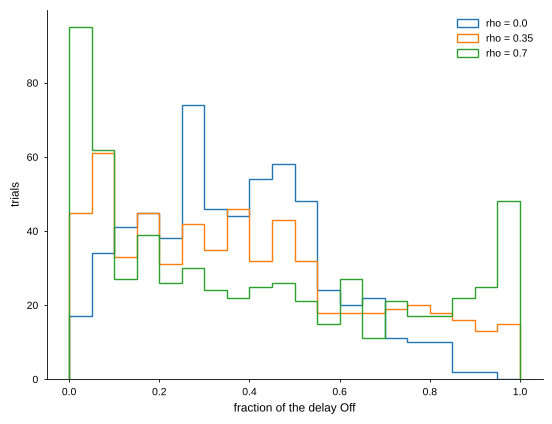

In [9]:
validL = (tzL >= 0) & (tzL <= 1400)
for rho in (0.0, 0.35, 0.7):
    rr = np.random.default_rng(3)
    st_ = onoff.label(c * dwL + readout.noise(dwL.shape, rho, rr), readout.null_threshold(dwL.shape, rho, rr), validL)
    plt.hist((st_[:, delay(tzL)] == -1).mean(1), np.linspace(0, 1, 21), histtype='step', label=f'rho = {rho}')
plt.xlabel('fraction of the delay Off'); plt.ylabel('trials'); plt.legend();
data_z = dict(np.load(paths.results('recordings', 'example_delay_z.npz')))     # the session closest to the mean
print(f"decoding strength: session {data_z['session']} {data_z['gmm_means'].max():.2f}, mean of sessions {target:.2f}, "
      f"model {m['mu_on_model']:.2f}")

## e-i. Validation on synthetic neurons

In [10]:
jobs = [(lev, k, 1000 * i + j) for i, (lev, k) in enumerate(LEVELS.items()) for j in range(N_SESSIONS)]
res = Parallel(n_jobs=-1)(delayed(synthetic.session)(k, seed) for _, k, seed in jobs)
syn = pd.DataFrame([dict(level=lev, **r) for (lev, _, _), (r, _) in zip(jobs, res)])
example = res[[s for *_, s in jobs].index(1000)][1]               # first session at the second strength
model = readout.evaluate(P, ses, n_trials=2112, seed=1)          # the model's gains for the three populations (g)
m['gains'] = {lab: model['sets'][lab]['gain'] for lab in ('rand 20', 'all', 'top 20')}
syn.groupby('level')[['mu_on_pipeline', 'gain_c', 'corr_z_pipeline_repeat', 'corr_z_pipeline_vs_shortcut',
                      'pipeline_n_on', 'shortcut_n_on', 'pipeline_n_off', 'shortcut_n_off']].mean().round(3)

,mu_on_pipeline,gain_c,corr_z_pipeline_repeat,corr_z_pipeline_vs_shortcut,pipeline_n_on,shortcut_n_on,pipeline_n_off,shortcut_n_off
level,,,,,,,,
medium,2.128,0.050,0.303,0.357,3.563,2.283,3.705,3.612
strong,3.984,0.086,0.538,0.603,4.562,3.320,2.221,2.620
weak,1.435,0.030,0.137,0.169,2.238,1.137,4.821,4.299


The shortcut read-out (`z = c dr + eta`) against the full pipeline (Poisson neurons, decoder), one dot per session;
and one trial both ways, with the true dips shaded.

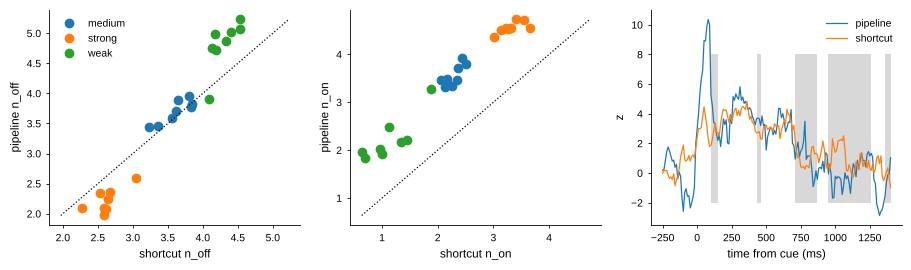

In [11]:
_, ax = plt.subplots(1, 3, figsize=(11, 2.8))
for a, st in zip(ax, ('n_off', 'n_on')):
    for lev, g in syn.groupby('level'):
        a.plot(g[f'shortcut_{st}'], g[f'pipeline_{st}'], 'o', label=lev)
    lim = [syn[[f'shortcut_{st}', f'pipeline_{st}']].values.min(), syn[[f'shortcut_{st}', f'pipeline_{st}']].values.max()]
    a.plot(lim, lim, 'k:'); a.set_xlabel(f'shortcut {st}'); a.set_ylabel(f'pipeline {st}')
ax[0].legend()
ax[2].plot(example['tt'], example['z_pipeline'], label='pipeline'); ax[2].plot(example['tt'], example['z_shortcut'], label='shortcut')
ttv = example['tt'][(example['tt'] >= 0) & (example['tt'] <= 1400)]
ax[2].fill_between(ttv, -2, 8, where=example['dip'], color='grey', alpha=0.3, lw=0)
ax[2].set_xlabel('time from cue (ms)'); ax[2].set_ylabel('z'); ax[2].legend();

## Figure

findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.


findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive


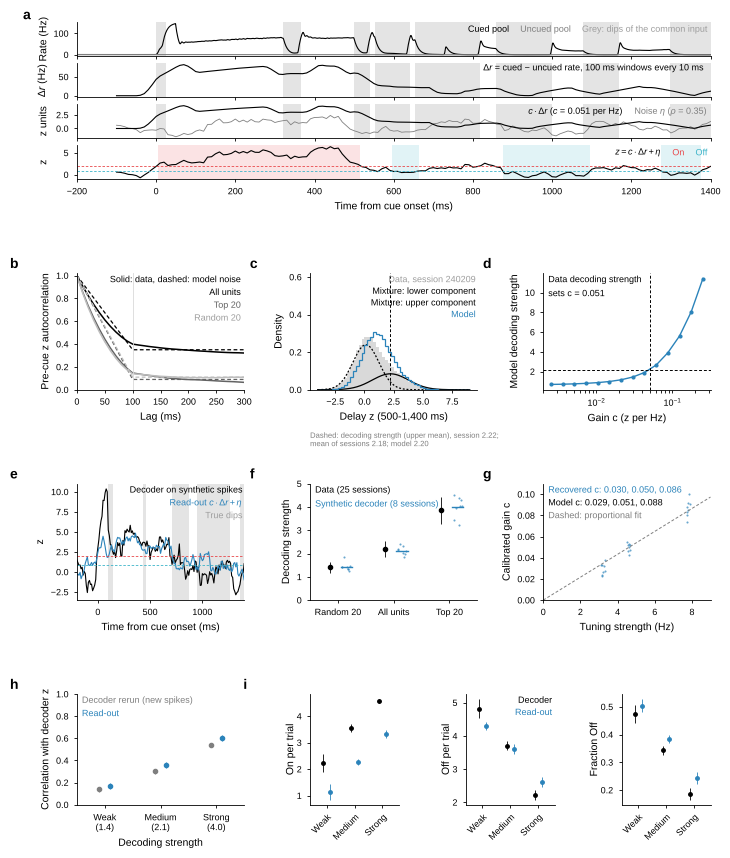

In [12]:
fig = figS1.draw(m, acf, data_z, syn, example, ses, readout.RHO, TARGETS)
style.save(fig, '../figures/figS1.png')